In [1]:
# =============================================================
# Sample Size Calculation — Riley et al. (2019) Method
# =============================================================
# Paper: Risk prediction of 72-hour fatality in panic-level hyperuricemia
#        using machine learning and logistic regression
# Journal: PLOS ONE (PONE-D-26-36706, revision R1)
# Outputs (final R1 numbering):
#   S1 Table -> S1_Table.xlsx, S1_Table.docx
#   S1 Fig   -> S1_Fig.tif (RGB, LZW, 600 dpi, 5.2 in wide)
#
# Environment: Google Colaboratory + R (pmsampsize via rpy2); versions are printed in Section 1
#
# NOTE: No patient data are used. The only study-derived inputs are the
#       development cohort size and event count (Fig 1, Table 1).
# =============================================================

# Sample size calculation (Riley et al. 2019)
**Tool**: R package `pmsampsize`, called from Python via `rpy2`.
**Scope**: Applied to the development of the final MLRA model only (Methods, Sample size estimation).
**Planning inputs**: binary outcome; prevalence 6.5% (midpoint of 6.0%–7.0%); 3–5 predictor parameters; Cox-Snell R² 0.10, 0.15, 0.20.
**Also computed**: the requirement for 43 candidate predictor parameters (Discussion, Limitations, sixth point).
Section 9 checks every sample-size statement in the manuscript against the values computed here.

Run all cells from top to bottom. On Colab, installing R takes about 3–5 minutes.

## Section 1 · Setup (R, rpy2, pmsampsize, python-docx)

In [2]:
import os, shutil, subprocess, sys

IN_COLAB = "google.colab" in sys.modules

# Colab provides R and rpy2; they are installed only if missing.
if shutil.which("R") is None:
    subprocess.run(["apt-get", "install", "-y", "-q", "r-base", "r-base-dev"], check=True)
_installed = []
for pkg, mod in [("rpy2", "rpy2"), ("python-docx", "docx"), ("openpyxl", "openpyxl")]:
    try:
        __import__(mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
        _installed.append(pkg)
if "rpy2" in _installed:
    raise SystemExit("rpy2 was newly installed. Restart the runtime (Runtime > Restart session), "
                     "then run all cells again.")

import rpy2.robjects as ro
from rpy2.robjects.packages import importr
ro.r('if (!requireNamespace("pmsampsize", quietly = TRUE)) '
     'install.packages("pmsampsize", repos = "https://cloud.r-project.org", quiet = TRUE)')
pms = importr("pmsampsize")

R_VERSION   = ro.r("R.version.string")[0]
PMS_VERSION = ro.r('as.character(packageVersion("pmsampsize"))')[0]
import platform, importlib.metadata as _md
RPY2_VERSION = _md.version("rpy2")
print(f"Python {platform.python_version()}; {R_VERSION}; pmsampsize {PMS_VERSION}; rpy2 {RPY2_VERSION}")

OUTPUT_DIR = "/content" if os.path.isdir("/content") else os.getcwd()
print("Output directory:", OUTPUT_DIR)

Python 3.13.18; R version 4.6.1 (2026-06-24); pmsampsize 1.1.3; rpy2 3.5.17
Output directory: /content


## Section 2 · Planning inputs and study counts
All numbers used below are defined here once.

In [3]:
assert "pms" in globals(), ("Section 1 (Setup) has not been run in this session. "
                              "Use Runtime > Run all, or run Section 1 first.")
# Planning inputs (pre-study)
PREVALENCE  = 0.065                 # anticipated outcome prevalence (midpoint of 6.0%–7.0%)
PARAMETERS  = [3, 4, 5]             # number of candidate predictor parameters
CS_R2       = [0.10, 0.15, 0.20]    # anticipated Cox-Snell R-squared
# Interpretive AUC ranges attached to each R-squared value (labels only; not inputs to pmsampsize)
AUC_LABEL   = {0.10: "0.70–0.75", 0.15: "0.75–0.80", 0.20: "0.80–0.85"}
R2_NAME     = {0.10: "Conservative", 0.15: "Realistic", 0.20: "Optimistic"}

# Riley et al. criteria (pmsampsize defaults for binary outcomes)
TARGET_SHRINKAGE = 0.90             # criterion 1
DELTA_NAGELKERKE = 0.05             # criterion 2: apparent − adjusted Nagelkerke R-squared
MARGIN_OVERALL   = 0.05             # criterion 3: margin of error of the overall outcome proportion

# Study counts (Results: Fig 1, Table 1, Table 3)
N_DEV, EVENTS_DEV   = 756, 48       # development cohort
N_MLRA, EVENTS_MLRA = 664, 45       # complete cases for the four MLRA predictors (sample used to fit MLRA)
MLRA_PARAMETERS     = 4             # four continuous predictors (three log-transformed), one parameter each

# Limitations (sixth point): regression model with all candidate predictors
N_CANDIDATE_PARAMETERS = 43

# Optional post hoc row (not described in the Methods; off by default).
# If switched on, it uses the MLRA sample and the MLRA parameter count; the R-squared remains an assumption.
INCLUDE_POSTHOC = False
POSTHOC_R2      = 0.20

print(f"Development cohort: {EVENTS_DEV}/{N_DEV} = {EVENTS_DEV/N_DEV:.4f}")
print(f"MLRA complete-case sample: {EVENTS_MLRA}/{N_MLRA} = {EVENTS_MLRA/N_MLRA:.4f}")

Development cohort: 48/756 = 0.0635
MLRA complete-case sample: 45/664 = 0.0678


## Section 3 · Minimum sample size for each scenario (pmsampsize)

In [4]:
assert "pms" in globals(), ("Section 1 (Setup) has not been run in this session. "
                              "Use Runtime > Run all, or run Section 1 first.")
import numpy as np
import pandas as pd

def run_pmsampsize(r2, p, prev):
    res = pms.pmsampsize(type="b", csrsquared=ro.FloatVector([r2]),
                         parameters=ro.IntVector([p]), prevalence=ro.FloatVector([prev]))
    tab = np.array(res.rx2("results_table"))          # rows: criteria 1–3, final
    return {
        "n_crit1": int(tab[0, 0]), "n_crit2": int(tab[1, 0]), "n_crit3": int(tab[2, 0]),
        "min_n": int(res.rx2("sample_size")[0]),
        "events": float(res.rx2("events")[0]),        # min_n × prevalence (unrounded)
        "shrinkage": float(res.rx2("final_shrinkage")[0]),
        "max_r2": float(res.rx2("max_r2a")[0]),
        "epp": float(res.rx2("EPP")[0]),
    }

rows = []
for p in PARAMETERS:
    for r2 in CS_R2:
        rows.append({"scenario": f"{p} parameters, {R2_NAME[r2].lower()}", "parameters": p,
                     "auc_label": AUC_LABEL[r2], "r2": r2, "prevalence": PREVALENCE,
                     "posthoc": False, **run_pmsampsize(r2, p, PREVALENCE)})
_posthoc = {"scenario": "Post hoc (MLRA sample)", "parameters": MLRA_PARAMETERS,
            "auc_label": "—", "r2": POSTHOC_R2, "prevalence": EVENTS_MLRA / N_MLRA, "posthoc": True,
            **run_pmsampsize(POSTHOC_R2, MLRA_PARAMETERS, EVENTS_MLRA / N_MLRA)}
print(f"[info] Post hoc calculation (MLRA sample, {MLRA_PARAMETERS} parameters, R² {POSTHOC_R2}): "
      f"minimum N {_posthoc['min_n']}; included in S1 Table: {INCLUDE_POSTHOC}\n")
if INCLUDE_POSTHOC:
    rows.append(_posthoc)
res_df = pd.DataFrame(rows)

with pd.option_context("display.width", 200, "display.max_columns", 20):
    print(res_df.drop(columns=["prevalence"]).round(4).to_string(index=False))

planning = res_df[~res_df.posthoc]
print(f"\nPlanning scenarios: minimum N {planning.min_n.min()}–{planning.min_n.max()}; "
      f"events {planning.events.round().min():.0f}–{planning.events.round().max():.0f}")
print(f"MLRA sample (n = {N_MLRA}; {EVENTS_MLRA} events) meets every minimum N and event count: "
      f"{bool((res_df.min_n <= N_MLRA).all() and (res_df.events.round() <= EVENTS_MLRA).all())}")

[info] Post hoc calculation (MLRA sample, 4 parameters, R² 0.2): minimum N 182; included in S1 Table: False

                  scenario  parameters auc_label   r2  posthoc  n_crit1  n_crit2  n_crit3  min_n  events  shrinkage  max_r2  epp
3 parameters, conservative           3 0.70–0.75 0.10    False      255      148       94    255  16.575     0.9000  0.3818 5.52
   3 parameters, realistic           3 0.75–0.80 0.15    False      165      144       94    165  10.725     0.9000  0.3818 3.57
  3 parameters, optimistic           3 0.80–0.85 0.20    False      120      140       94    140   9.100     0.9129  0.3818 3.03
4 parameters, conservative           4 0.70–0.75 0.10    False      340      197       94    340  22.100     0.9000  0.3818 5.53
   4 parameters, realistic           4 0.75–0.80 0.15    False      220      192       94    220  14.300     0.9000  0.3818 3.58
  4 parameters, optimistic           4 0.80–0.85 0.20    False      160      186       94    186  12.090     0.9129  

## Section 3b · Requirement for 43 candidate predictor parameters (Limitations)
The Riley minimum is the largest of criteria 1–3 (reported in the Limitations); criterion 1 alone is shown for reference only. Prevalence 6.5%.

In [5]:
assert "pms" in globals(), ("Section 1 (Setup) has not been run in this session. "
                              "Use Runtime > Run all, or run Section 1 first.")
lim = []
for r2 in CS_R2:
    o = run_pmsampsize(r2, N_CANDIDATE_PARAMETERS, PREVALENCE)
    lim.append({"r2": r2, "n_crit1_shrinkage": o["n_crit1"], "n_crit2": o["n_crit2"],
                "n_crit3": o["n_crit3"], "min_n_all_criteria": o["min_n"]})
lim_df = pd.DataFrame(lim)
print(lim_df.to_string(index=False))
LIM_C1  = (lim_df.n_crit1_shrinkage.min(), lim_df.n_crit1_shrinkage.max())
LIM_ALL = (lim_df.min_n_all_criteria.min(), lim_df.min_n_all_criteria.max())
print(f"\nCriterion 1 only : {LIM_C1[0]:,}–{LIM_C1[1]:,}")
print(f"All three criteria: {LIM_ALL[0]:,}–{LIM_ALL[1]:,}")

  r2  n_crit1_shrinkage  n_crit2  n_crit3  min_n_all_criteria
0.10               3651     2116       94                3651
0.15               2359     2056       94                2359
0.20               1712     1996       94                1996

Criterion 1 only : 1,712–3,651
All three criteria: 1,996–3,651


## Section 4 · Verification from the definitions of the criteria
Independent path: the three criteria of Riley et al. are recomputed in closed form, and the properties
that must hold at the final sample size are checked. Any failure stops the notebook.

In [6]:
assert "pms" in globals(), ("Section 1 (Setup) has not been run in this session. "
                              "Use Runtime > Run all, or run Section 1 first.")
from math import ceil, log, sqrt, exp
from scipy.optimize import brentq

def riley_closed_form(r2, p, prev, S=TARGET_SHRINKAGE, delta=DELTA_NAGELKERKE, m=MARGIN_OVERALL):
    n1 = ceil(p / ((S - 1) * log(1 - r2 / S)))
    E1 = n1 * prev
    lnLnull = E1 * log(E1 / n1) + (n1 - E1) * log(1 - E1 / n1)
    max_r2 = 1 - exp(2 * lnLnull / n1)
    S2 = r2 / (r2 + delta * max_r2)
    n2 = ceil(p / ((S2 - 1) * log(1 - r2 / S2)))
    n3 = ceil((1.96 / m) ** 2 * prev * (1 - prev))
    return n1, n2, n3, max(n1, n2, n3), max_r2

def expected_shrinkage(n, r2, p):
    """Solve n = p / ((S − 1) ln(1 − R2/S)) for S (Riley et al., criterion 1)."""
    f = lambda S: p / ((S - 1) * log(1 - r2 / S)) - n
    return brentq(f, r2 + 1e-9, 1 - 1e-9)

checks = []
for _, r in res_df.iterrows():
    n1, n2, n3, nf, mx = riley_closed_form(r.r2, r.parameters, r.prevalence)
    S_n = expected_shrinkage(r.min_n, r.r2, r.parameters)
    nag_diff = (r.r2 / S_n - r.r2) / mx                 # apparent − adjusted Nagelkerke R-squared
    moe = 1.96 * sqrt(r.prevalence * (1 - r.prevalence) / r.min_n)
    ok = {
        "criteria_match": (n1, n2, n3, nf) == (r.n_crit1, r.n_crit2, r.n_crit3, r.min_n),
        "events_def":     abs(r.events - r.min_n * r.prevalence) < 1e-9,
        "shrinkage>=0.90": S_n >= TARGET_SHRINKAGE - 1e-6,
        "nagelkerke<=0.05": nag_diff <= DELTA_NAGELKERKE + 1e-6,
        "margin<=0.05":   moe <= MARGIN_OVERALL + 1e-9,
        "shrinkage_reported": abs(S_n - r.shrinkage) < 0.005,
    }
    checks.append({"scenario": r.scenario, "min_n": r.min_n, "S(n)": round(S_n, 4),
                   "Nagelkerke diff": round(nag_diff, 4), "margin": round(moe, 4), **ok})
for _, r in lim_df.iterrows():
    n1, n2, n3, nf, _mx = riley_closed_form(r.r2, N_CANDIDATE_PARAMETERS, PREVALENCE)
    checks.append({"scenario": f"43 parameters, R² {r.r2:.2f}", "min_n": nf,
                   "criteria_match": (n1, n2, n3, nf) == (r.n_crit1_shrinkage, r.n_crit2, r.n_crit3, r.min_n_all_criteria)})
chk = pd.DataFrame(checks)
print(chk.astype(object).where(chk.notna(), "").to_string(index=False))
flag_cols = [c for c in chk.columns if c in ok]
assert chk[flag_cols].fillna(True).astype(bool).all().all(), "HALT: a definition-derived property failed."
print("\nAll definition-derived checks passed.")

                  scenario min_n    S(n) Nagelkerke diff  margin criteria_match events_def shrinkage>=0.90 nagelkerke<=0.05 margin<=0.05 shrinkage_reported
3 parameters, conservative   255  0.9001          0.0291  0.0303           True       True            True             True         True               True
   3 parameters, realistic   165  0.9002          0.0435  0.0376           True       True            True             True         True               True
  3 parameters, optimistic   140  0.9133          0.0497  0.0408           True       True            True             True         True               True
4 parameters, conservative   340  0.9001          0.0291  0.0262           True       True            True             True         True               True
   4 parameters, realistic   220  0.9002          0.0435  0.0326           True       True            True             True         True               True
  4 parameters, optimistic   186   0.913          0.0499  0.0354

/tmp/ipykernel_3469/2311223257.py:44: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  assert chk[flag_cols].fillna(True).astype(bool).all().all(), "HALT: a definition-derived property failed."


## Section 5 · Sensitivity to the anticipated prevalence (not reported in the manuscript)
The Methods state an anticipated prevalence of 6.0%–7.0%; S1 Table uses the midpoint (6.5%).
This cell shows the minimum sample size for five parameters across that range.

In [7]:
assert "pms" in globals(), ("Section 1 (Setup) has not been run in this session. "
                              "Use Runtime > Run all, or run Section 1 first.")
sens = []
for prev in [0.060, 0.065, 0.070]:
    for r2 in CS_R2:
        o = run_pmsampsize(r2, 5, prev)
        sens.append({"prevalence": prev, "r2": r2, "min_n": o["min_n"],
                     "events": round(o["events"]), "shrinkage": round(o["shrinkage"], 3)})
sens_df = pd.DataFrame(sens)
print(sens_df.to_string(index=False))
print(f"Range of minimum N: {sens_df.min_n.min()}–{sens_df.min_n.max()} (MLRA sample n = {N_MLRA})")

 prevalence   r2  min_n  events  shrinkage
      0.060 0.10    425      26      0.900
      0.060 0.15    275      16      0.900
      0.060 0.20    243      15      0.916
      0.065 0.10    425      28      0.900
      0.065 0.15    275      18      0.900
      0.065 0.20    233      15      0.913
      0.070 0.10    425      30      0.900
      0.070 0.15    275      19      0.900
      0.070 0.20    223      16      0.910
Range of minimum N: 223–425 (MLRA sample n = 664)


## Section 6 · S1 Table — inline display

In [8]:
assert "pms" in globals(), ("Section 1 (Setup) has not been run in this session. "
                              "Use Runtime > Run all, or run Section 1 first.")
S1_TITLE = ("S1 Table. Sample size estimation for prediction model development "
            "based on the criteria of Riley et al. [31].")

s1 = pd.DataFrame({
    "Scenario": [("Post hoc" if r.posthoc else R2_NAME[r.r2]) for r in res_df.itertuples()],
    "Predictor parameters": res_df.parameters.astype(int),
    "Anticipated AUC": res_df.auc_label,
    "Cox-Snell R²": res_df.r2.map(lambda v: f"{v:.2f}"),
    "Prevalence": res_df.prevalence.map(lambda v: f"{100*v:.2f}%" if v != PREVALENCE else f"{100*v:.1f}%"),
    "Minimum sample size": res_df.min_n.astype(int),
    "Events": res_df.events.map(lambda v: f"{v:.0f}"),
    "Shrinkage factor": res_df.shrinkage.map(lambda v: f"{v:.3f}"),
    "EPP": res_df.epp.map(lambda v: f"{v:.1f}"),
})

S1_FOOTNOTE = (
    f"Minimum sample sizes were calculated with the pmsampsize R package (version {PMS_VERSION}) "
    f"for a binary outcome. The minimum sample size is the largest of the sizes required to meet "
    f"three criteria: (1) an expected shrinkage factor of ≥{TARGET_SHRINKAGE:.2f}; (2) an absolute "
    f"difference of ≤{DELTA_NAGELKERKE:.2f} between the apparent and adjusted Nagelkerke R²; and "
    f"(3) a margin of error of ≤{MARGIN_OVERALL:.2f} in the estimated overall outcome proportion. "
    f"Planning scenarios assumed an outcome prevalence of {100*PREVALENCE:.1f}%. "
    f"Events were calculated as the minimum sample size multiplied by the prevalence. "
    f"Anticipated AUC ranges are interpretive labels for each Cox-Snell R² and were not inputs to the calculation. "
    + (f"The post hoc row applies the same method with the observed event rate in the complete-case sample "
       f"used to develop the final MLRA model ({EVENTS_MLRA}/{N_MLRA}, {100*EVENTS_MLRA/N_MLRA:.2f}%), "
       f"{MLRA_PARAMETERS} predictor parameters, and an assumed Cox-Snell R² of {POSTHOC_R2:.2f}. "
       if INCLUDE_POSTHOC else "")
    + f"The complete-case sample used to develop the final MLRA model (n = {N_MLRA}; {EVENTS_MLRA} events) "
      f"met the minimum sample size and number of events in all scenarios."
)
S1_ABBREV = ("Abbreviations: AUC, area under the receiver operating characteristic curve; "
             "EPP, events per predictor parameter; MLRA, multivariable logistic regression analysis; "
             "R², coefficient of determination.")

assert (res_df.min_n <= N_MLRA).all() and (res_df.events.round() <= EVENTS_MLRA).all()  # last footnote sentence
if not INCLUDE_POSTHOC:
    s1 = s1.drop(columns=["Prevalence"])   # constant (6.5%) in all rows; stated in the footnote
from IPython.display import display, Markdown
display(Markdown(f"**{S1_TITLE}**"))
display(s1.style.hide(axis="index"))
display(Markdown(S1_FOOTNOTE + "\n\n*" + S1_ABBREV + "*"))

**S1 Table. Sample size estimation for prediction model development based on the criteria of Riley et al. [31].**

Scenario,Predictor parameters,Anticipated AUC,Cox-Snell R²,Minimum sample size,Events,Shrinkage factor,EPP
Conservative,3,0.70–0.75,0.10,255,17,0.900,5.5
Realistic,3,0.75–0.80,0.15,165,11,0.900,3.6
Optimistic,3,0.80–0.85,0.20,140,9,0.913,3.0
Conservative,4,0.70–0.75,0.10,340,22,0.900,5.5
Realistic,4,0.75–0.80,0.15,220,14,0.900,3.6
Optimistic,4,0.80–0.85,0.20,186,12,0.913,3.0
Conservative,5,0.70–0.75,0.10,425,28,0.900,5.5
Realistic,5,0.75–0.80,0.15,275,18,0.900,3.6
Optimistic,5,0.80–0.85,0.20,233,15,0.913,3.0


Minimum sample sizes were calculated with the pmsampsize R package (version 1.1.3) for a binary outcome. The minimum sample size is the largest of the sizes required to meet three criteria: (1) an expected shrinkage factor of ≥0.90; (2) an absolute difference of ≤0.05 between the apparent and adjusted Nagelkerke R²; and (3) a margin of error of ≤0.05 in the estimated overall outcome proportion. Planning scenarios assumed an outcome prevalence of 6.5%. Events were calculated as the minimum sample size multiplied by the prevalence. Anticipated AUC ranges are interpretive labels for each Cox-Snell R² and were not inputs to the calculation. The complete-case sample used to develop the final MLRA model (n = 664; 45 events) met the minimum sample size and number of events in all scenarios.

*Abbreviations: AUC, area under the receiver operating characteristic curve; EPP, events per predictor parameter; MLRA, multivariable logistic regression analysis; R², coefficient of determination.*

## Section 7 · S1 Fig — draw, save as TIFF, and display the saved file

Font used: Liberation Sans
S1_Fig.tif: 3120 × 2040 px = 5.20 × 3.40 in; dpi (600.0, 600.0); mode RGB; compression tiff_lzw


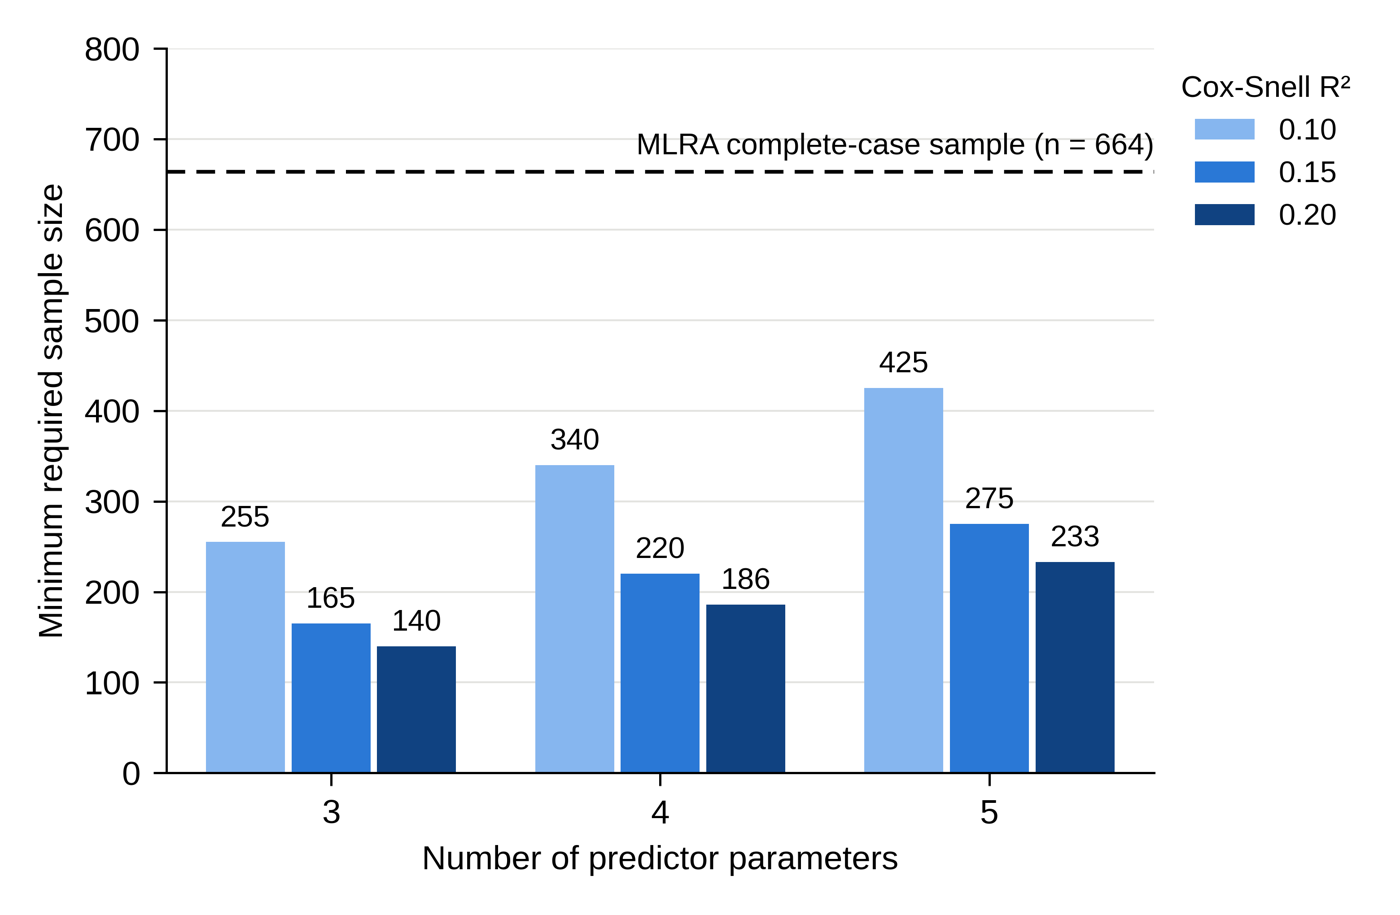

In [9]:
assert "pms" in globals(), ("Section 1 (Setup) has not been run in this session. "
                              "Use Runtime > Run all, or run Section 1 first.")
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image
from IPython.display import display

# Arial if installed; otherwise Liberation Sans (metrically identical to Arial)
_avail = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Arial", "Liberation Sans", "DejaVu Sans"] if f in _avail))
print("Font used:", FONT)
plt.rcParams.update({"font.family": FONT, "font.size": 9, "axes.linewidth": 0.6,
                     "xtick.major.width": 0.6, "ytick.major.width": 0.6})

FIG_W_IN, FIG_H_IN, DPI = 5.2, 3.4, 600            # PLOS: ≤ 7.5 in wide (5.2 in = one column)
COLORS = {0.10: "#86b6ef", 0.15: "#2a78d6", 0.20: "#104281"}   # ordinal one-hue ramp, light → dark

plot_df = res_df[~res_df.posthoc]
assert set(plot_df.parameters) == set(PARAMETERS) and set(plot_df.r2) == set(CS_R2)
fig, ax = plt.subplots(figsize=(FIG_W_IN, FIG_H_IN))
bw = 0.26
for k, r2 in enumerate(CS_R2):
    d = plot_df[plot_df.r2 == r2].sort_values("parameters")
    x = np.arange(len(PARAMETERS)) + (k - 1) * bw
    bars = ax.bar(x, d.min_n, width=bw - 0.02, color=COLORS[r2], label=f"{r2:.2f}", zorder=2)
    for xi, n in zip(x, d.min_n):
        ax.text(xi, n + 10, f"{n}", ha="center", va="bottom", fontsize=8)
ax.axhline(N_MLRA, color="black", linestyle=(0, (5, 3)), linewidth=1.0, zorder=3)
ax.text(len(PARAMETERS) - 0.5, N_MLRA + 12, f"MLRA complete-case sample (n = {N_MLRA})",
        ha="right", va="bottom", fontsize=8)
ax.set_xticks(np.arange(len(PARAMETERS)), [str(p) for p in PARAMETERS])
ax.set_xlim(-0.5, len(PARAMETERS) - 0.5)
ax.set_ylim(0, 800)
ax.set_xlabel("Number of predictor parameters")
ax.set_ylabel("Minimum required sample size")
ax.yaxis.grid(True, color="#e3e3e0", linewidth=0.5, zorder=0)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.legend(title="Cox-Snell R²", frameon=False, fontsize=8, title_fontsize=8,
          loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()

S1_FIG = os.path.join(OUTPUT_DIR, "S1_Fig.tif")
_png = os.path.join(OUTPUT_DIR, "_s1_fig_tmp.png")
fig.savefig(_png, dpi=DPI)                           # fixed canvas: no bbox cropping, so size = 5.2 × 3.4 in
plt.close(fig)
Image.open(_png).convert("RGB").save(S1_FIG, format="TIFF", compression="tiff_lzw", dpi=(DPI, DPI))
os.remove(_png)

im = Image.open(S1_FIG)
w_in, h_in = im.size[0] / DPI, im.size[1] / DPI
print(f"{os.path.basename(S1_FIG)}: {im.size[0]} × {im.size[1]} px = {w_in:.2f} × {h_in:.2f} in; "
      f"dpi {im.info.get('dpi')}; mode {im.mode}; compression {im.info.get('compression')}")
assert im.mode == "RGB" and im.info.get("compression") == "tiff_lzw"
assert w_in <= 7.5 + 1e-6 and h_in <= 8.75 + 1e-6

# Display the saved TIFF (what will be submitted), not the in-memory figure
_prev = im.copy(); _prev.thumbnail((1400, 1400))
display(_prev)

## Section 8 · S1 Table — export (xlsx, docx)

In [10]:
assert "pms" in globals(), ("Section 1 (Setup) has not been run in this session. "
                              "Use Runtime > Run all, or run Section 1 first.")
import openpyxl
from openpyxl.styles import Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter
import docx
from docx.shared import Pt, Inches
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.section import WD_ORIENT
from docx.oxml.ns import qn
from docx.oxml import OxmlElement

NUMERIC_COLS = ["Predictor parameters", "Minimum sample size"]

# ---- xlsx ----
S1_XLSX = os.path.join(OUTPUT_DIR, "S1_Table.xlsx")
wb = openpyxl.Workbook(); ws = wb.active; ws.title = "S1 Table"
ncol = s1.shape[1]
thin = Side(style="thin")
ws.cell(1, 1, S1_TITLE).font = Font(name="Arial", size=10, bold=True)
ws.merge_cells(start_row=1, start_column=1, end_row=1, end_column=ncol)
for j, h in enumerate(s1.columns, 1):
    c = ws.cell(3, j, h); c.font = Font(name="Arial", size=10, bold=True)
    c.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    c.border = Border(top=thin, bottom=thin)
for i, row in enumerate(s1.itertuples(index=False), 4):
    for j, v in enumerate(row, 1):
        c = ws.cell(i, j, int(v) if s1.columns[j-1] in NUMERIC_COLS else v)
        c.font = Font(name="Arial", size=10)
        c.alignment = Alignment(horizontal="left" if j == 1 else "center")
last = 3 + len(s1)
for j in range(1, ncol + 1):
    ws.cell(last, j).border = Border(bottom=thin)
for k, txt in enumerate([S1_FOOTNOTE, S1_ABBREV]):
    r = last + 2 + k
    ws.cell(r, 1, txt).font = Font(name="Arial", size=9)
    ws.cell(r, 1).alignment = Alignment(wrap_text=True, vertical="top")
    ws.merge_cells(start_row=r, start_column=1, end_row=r, end_column=ncol)
    ws.row_dimensions[r].height = 120 if k == 0 else 28
for j, w in enumerate([16, 12, 13, 12, 12, 14, 9, 12, 8][:ncol], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
wb.save(S1_XLSX)

# ---- docx ----
S1_DOCX = os.path.join(OUTPUT_DIR, "S1_Table.docx")
d = docx.Document()
sec = d.sections[0]
sec.orientation = WD_ORIENT.LANDSCAPE
sec.page_width, sec.page_height = Inches(11), Inches(8.5)
for m in ["left_margin", "right_margin", "top_margin", "bottom_margin"]:
    setattr(sec, m, Inches(1))
st = d.styles["Normal"]; st.font.name = "Arial"; st.font.size = Pt(10)
st.element.rPr.rFonts.set(qn("w:eastAsia"), "Arial")

def _border(cell, **edges):
    tcPr = cell._tc.get_or_add_tcPr()
    b = OxmlElement("w:tcBorders")
    for e, val in edges.items():
        el = OxmlElement(f"w:{e}"); el.set(qn("w:val"), val); el.set(qn("w:sz"), "4")
        el.set(qn("w:color"), "000000"); b.append(el)
    tcPr.append(b)

p = d.add_paragraph(); r = p.add_run(S1_TITLE); r.bold = True
t = d.add_table(rows=1 + len(s1), cols=ncol)
for j, h in enumerate(s1.columns):
    c = t.cell(0, j); c.text = ""; run = c.paragraphs[0].add_run(h); run.bold = True
    c.paragraphs[0].alignment = WD_ALIGN_PARAGRAPH.CENTER
    _border(c, top="single", bottom="single")
for i, row in enumerate(s1.itertuples(index=False), 1):
    for j, v in enumerate(row):
        c = t.cell(i, j); c.text = str(v)
        c.paragraphs[0].alignment = WD_ALIGN_PARAGRAPH.LEFT if j == 0 else WD_ALIGN_PARAGRAPH.CENTER
        if i == len(s1):
            _border(c, bottom="single")
for txt, size in [(S1_FOOTNOTE, 9), (S1_ABBREV, 9)]:
    fp = d.add_paragraph(); fr = fp.add_run(txt); fr.font.size = Pt(size)
d.save(S1_DOCX)

# Round-trip check: the exported files contain exactly the displayed table
chk_x = pd.read_excel(S1_XLSX, header=2, nrows=len(s1), dtype=str)
assert list(chk_x.columns) == list(s1.columns)
assert (chk_x.values == s1.astype(str).values).all()
dd = docx.Document(S1_DOCX).tables[0]
assert [[c.text for c in r.cells] for r in dd.rows[1:]] == s1.astype(str).values.tolist()
print("Exported:", S1_XLSX); print("Exported:", S1_DOCX); print("Exported:", S1_FIG)

Exported: /content/S1_Table.xlsx
Exported: /content/S1_Table.docx
Exported: /content/S1_Fig.tif


## Section 9 · Cross-check against the manuscript (R1, 20261027 version)
Each sample-size statement in the manuscript is compared with the values computed above. Any mismatch stops the notebook.

In [11]:
assert "pms" in globals(), ("Section 1 (Setup) has not been run in this session. "
                              "Use Runtime > Run all, or run Section 1 first.")
plan = res_df[~res_df.posthoc]
def row(p, r2):
    return plan[(plan.parameters == p) & (np.isclose(plan.r2, r2))].iloc[0]
c5, o5 = row(5, 0.10), row(5, 0.20)
ev = plan.events.round().astype(int)
xcheck = [
    ("Methods: prevalence 6.5%, midpoint of 6.0%–7.0%", f"{100*PREVALENCE:.1f}%", np.isclose(PREVALENCE, (0.06 + 0.07) / 2)),
    ("Methods: three to five predictors", f"{min(PARAMETERS)}–{max(PARAMETERS)}", PARAMETERS == [3, 4, 5]),
    ("Methods: Cox-Snell R² 0.10–0.20", f"{min(CS_R2):.2f}–{max(CS_R2):.2f}", CS_R2 == [0.10, 0.15, 0.20]),
    ("Methods: minimum N 140 to 425", f"{plan.min_n.min()}–{plan.min_n.max()}", (plan.min_n.min(), plan.min_n.max()) == (140, 425)),
    ("Methods: 9–28 events", f"{ev.min()}–{ev.max()}", (ev.min(), ev.max()) == (9, 28)),
    ("Results: five-predictor conservative N = 425, 28 events", f"{c5.min_n}, {c5.events:.0f}", (c5.min_n, round(c5.events)) == (425, 28)),
    ("Results: five-predictor optimistic N = 233, 15 events", f"{o5.min_n}, {o5.events:.0f}", (o5.min_n, round(o5.events)) == (233, 15)),
    ("Results: MLRA sample (664; 45) meets all scenarios", f"max N {plan.min_n.max()}, max events {ev.max()}",
     plan.min_n.max() <= N_MLRA and ev.max() <= EVENTS_MLRA),
    ("Limitations: same criteria, 43 parameters → approx. 2,000–3,700", f"{LIM_ALL[0]:,}–{LIM_ALL[1]:,}",
     (round(LIM_ALL[0], -2), round(LIM_ALL[1], -2)) == (2000, 3700)),
]
xc = pd.DataFrame(xcheck, columns=["Manuscript statement", "Computed", "Match"])
print(xc.to_string(index=False))
print(f"\n[info] Criterion 1 alone (not the Riley minimum): {LIM_C1[0]:,}–{LIM_C1[1]:,}")
assert xc.Match.all(), "HALT: a manuscript statement does not match the computed values."

                                           Manuscript statement                 Computed  Match
                Methods: prevalence 6.5%, midpoint of 6.0%–7.0%                     6.5%   True
                              Methods: three to five predictors                      3–5   True
                                Methods: Cox-Snell R² 0.10–0.20                0.10–0.20   True
                                  Methods: minimum N 140 to 425                  140–425   True
                                           Methods: 9–28 events                     9–28   True
        Results: five-predictor conservative N = 425, 28 events                  425, 28   True
          Results: five-predictor optimistic N = 233, 15 events                  233, 15   True
             Results: MLRA sample (664; 45) meets all scenarios max N 425, max events 28   True
Limitations: same criteria, 43 parameters → approx. 2,000–3,700              1,996–3,651   True

[info] Criterion 1 alone (not the Riley

## Section 10 · Download (Colab)

In [12]:
assert "pms" in globals(), ("Section 1 (Setup) has not been run in this session. "
                              "Use Runtime > Run all, or run Section 1 first.")
if IN_COLAB:
    from google.colab import files
    for f in [S1_FIG, S1_XLSX, S1_DOCX]:
        files.download(f)
else:
    print("Not running on Colab; files are in", OUTPUT_DIR)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Change log (R1, 2026-10-28)
| # | Change | Reason |
|---|---|---|
| 1 | Output file names and titles aligned with the final numbering (S1 Table, S1 Fig): `S1_Table.xlsx`, `S1_Table.docx`, `S1_Fig.tif` | R1 numbering |
| 2 | S1 Table now generated with all nine planning scenarios (previous export cell produced four rows only) | Match the submitted S1 Table |
| 3 | Hard-coded reference values removed; verification recomputes the three criteria in closed form and checks definition-derived properties (shrinkage ≥ 0.90, Nagelkerke difference ≤ 0.05, margin ≤ 0.05) | Values must be computed in the notebook |
| 4 | Displayed values equal the calculation inputs (parameters, R²); AUC labels marked as interpretive | Display must match computation |
| 5 | Footnote: criteria 2 and 3 described as defined by Riley et al.; "pre-specified", bold, and † markers removed; EPV → EPP | Definitions; no protocol citation for "pre-specified" |
| 6 | S1 Fig saved as TIFF (5.2 in wide, 600 dpi, RGB, LZW, Arial/Liberation Sans 8–9 pt); no title inside the image; bar values shown | PLOS figure requirements |
| 7 | Japanese console output and the unpublished AUC-to-R² heuristic cell removed; prevalence sensitivity kept as a non-reported check | English S1 Code; no unnamed heuristic presented as a formula |
| 8 | Reference sample for the sufficiency statement changed from the development cohort (756; 48) to the complete-case sample used to fit MLRA (664; 45), in the footnote and S1 Fig | Methods: the calculation applies only to the final MLRA model |
| 9 | Post hoc row removed by default (`INCLUDE_POSTHOC = False`); if switched on, it uses the MLRA sample and four parameters | Not described in the Methods; previous row mixed 756/48, five parameters, and an assumed R² |
| 10 | Section 3b added: requirement for 43 candidate predictor parameters (Limitations) | The value in the Limitations was not computed in any notebook |
| 11 | Section 9 added: automated cross-check of every sample-size statement in the manuscript | Values must come from code |
| 12 | Each cell after Section 1 stops with a message if Section 1 has not been run | NameError when cells were run without Section 1 |
| 13 | Limitations value checked against the Riley minimum (largest of criteria 1–3: 1,996–3,651) instead of criterion 1 alone (1,712–3,651) | The minimum sample size is defined by all three criteria |